North Eastern Realty Group: A Qualitative Data Analysis of Local Power Balances;Buyer & Seller Real Estate Markets|
------------------------------------------------------------------------------------------------------------------

Jedidiah C. Kachika

Contacts: Phone; 1(260)348-2062, Personal/Work Email; Jedikachika@icloud.com, School Email; Jedidiah.Kachika@students.sacs.k12.in.us, Jedidiah.Kachika@fwcsstudents.org

 Homestead Highschool 4310 Homestead Rd, Fort Wayne, IN 46814, Amp Lab Senior Highschool 1030 Swinney Ave, Fort Wayne, IN 46802

---
## Abstract
---
In this analytical study, we explore local buyer and seller markets to identify shift-prone regions within the Upstate Alliance cluster of counties. By assessing correlating metrics and refining our definition of what qualifies as a buyer or seller market in real estate, this investigation provides insight into the defining traits of real estate power balance, months of supply (MoS), and its fluctuations. This analysis evaluates outlying regions characterized by anomalous market shifts to uncover the underlying drivers of that volatility.
---

### Table of Contents
----

#### Section 1 - Initial Methodology

    1.A - Loading Intial Raw Data

    1.B - Market Classification

    1.C - Conclusions

#### Section 2 - Jay County Investigation

    2.A - Observing Changes In Jay

    2.B - Understanding The Why

    2.C - Takeaway

#### Section 3 - Trend Investigation: Why is Upstate in a Seller Market?

    3.A - Evaluating Trend-Conforming Counties

    3.B - Indepth Observations

    3.C Conclusions



#### Section 4 - Prediction Model Value Your Time and Money

    4.A How Many of You Value Your Time?

    4.B How It Works: Limits & Capabilites 
    
    4.C Takeaway


## Libaries / Toolkit

In [20]:

import sqlite3  # noqa: I001

import seaborn as sns 
import matplotlib.pyplot as plt       


import numpy as np                                                                                                                                             
import pandas as pd 

from pathlib import Path 

from sklearn import tree                                                                                                                                                                                                               
from sklearn.ensemble import RandomForestClassifier                                                                                                                                                            
from sklearn.ensemble import RandomForestRegressor                                                                                            
from sklearn.metrics import mean_absolute_error                                                                                                                                                                


clf = tree.DecisionTreeClassifier()               

model = RandomForestClassifier()                                                                             




conn = sqlite3.connect('../database/realty.db')               








---

#### 1.A) Reading, Interpreting, and Organizing Redfin’s Raw Data
Before analyzing any data, we needed to read and filter it to a local degree. Additionally, the data had to be organized chronologically.

(“Computer programs do not know datetimes; using pandas, raw data was converted to datetimes.” Documentation: https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html)

After reading and purifying our raw data, it was ready for interpretation. The first step was calculating MoS. There are several ways to calculate it, including inventory/homes sold, active listings/pending sales, and others. The formula used for this project is (inventory / 12-month trailing homes sold / 12). This formula was chosen because it is used by the IRA Hub and makes cross-checking MoS values straightforward. Additionally, this formula smooths out MoS values over time.



In [21]:

df = pd.read_csv('../data/raw/RedFinHousingMarketDataMetrics.csv')                                                                                                                                                                                                                   

counties = ['Adams County, IN', 'Allen County, IN', 'Jay County, IN', 'Huntington County, IN', 'Wells County, IN', 'Whitley County, IN']                                                                                                                                                                       

df_NEast = df[df['REGION NAME'].isin(counties)].copy()                                                                                                                                                                                                           

df_NEast['PERIOD BEGIN'] = pd.to_datetime(df_NEast['PERIOD BEGIN'])                                                                                                                                                                                                                                
df_NEast['PERIOD END'] = pd.to_datetime(df_NEast['PERIOD END'])                 

df_NEast = df_NEast.sort_values(['REGION NAME', 'PERIOD BEGIN'])  
                                                                                                                                                                                                        
df_NEast['CLOSED SALES TRAILING 12MO'] = df_NEast.groupby('REGION NAME')['HOMES SOLD'].rolling(12).sum().reset_index(level=0, drop=True)                                                                                                                                                                                                  
df_NEast['TRUE MOS'] = df_NEast['INVENTORY'] / (df_NEast['CLOSED SALES TRAILING 12MO'] / 12)
df_NEast['MONTHS OF SUPPLY'] = df_NEast['TRUE MOS']
df_NEast = df_NEast.rename(columns={"MONTHS OF SUPPLY": "MOS"})
df_NEast[['MOS', 'TRUE MOS']]
are_identical = df_NEast['MOS'].equals(df_NEast['TRUE MOS'])
print(are_identical)

True


---

#### 1.B) Market Condition Definition and Initial Market Observations
We know that market classifications show the ratio between available homes and buyer demand. In a seller’s market, there is an observable surplus of buyer demand but a limited supply of properties on the market (“Zillow”). This, in turn, leads to competitive bidding, higher sale prices, and fewer days on the market. The opposite is true for buyer’s markets. On the other hand, balanced markets are those in which there is no clear buyer or seller advantage.

###### (Sources: https://www.zillow.com/learn/buyers-or-sellers-market/)

Market state is classified by how many months it would take to sell all homes in a specific region (MoS). A buyer’s market is classified when MoS is greater than or equal to six. This means that if it takes six months or more to sell all homes in the market, the pace of sales has slowed significantly. A slow pace affects how much profit realtors see because it dictates how much leverage sellers have over buyers.

###### (Sources: https://www.uspropertystats.com/days-on-market/, https://showingtime.com/resources/blog/everything-you-need-know-about-months-supply-inventory)




In [22]:
                                                                                                                                                                                                                          
                                              
def classify_market(months_of_supply):
    if pd.isna(months_of_supply):
        return 'No data accounted'
    elif months_of_supply > 6:
        return 'Buyer Market'
    elif months_of_supply < 4:
        return 'Seller Market'
    else:
        return 'Balanced Market'
df_NEast['MARKET SIGNAL'] = df_NEast['MOS'].apply(classify_market)                                                                                                                                                                             

df_NEast['PREVIOUS SIGNAL'] = df_NEast.groupby('REGION NAME')['MARKET SIGNAL'].shift(1)                                                                                                                                                         
                                                                                     
changed = df_NEast[(df_NEast['MARKET SIGNAL'] != df_NEast['PREVIOUS SIGNAL']) & (df_NEast['PREVIOUS SIGNAL'].notna())]                                                                                                                                                                                                                                                                                                                                   

Recent_shifts = changed.groupby('REGION NAME').tail(1)                                                              

current_status = df_NEast.groupby('REGION NAME').tail(1)                                          

Huntintongcheck = df_NEast[(df_NEast['REGION NAME'] == 'Huntintong County, IN')].copy()
Huntintongcheck[['PERIOD BEGIN', 'MOS']]

Recent_shifts[['REGION NAME', 'PERIOD BEGIN', 'MARKET SIGNAL', 'PREVIOUS SIGNAL', 'MOS']]
changed[['REGION NAME', 'PERIOD BEGIN', 'MARKET SIGNAL', 'PREVIOUS SIGNAL', 'MOS']]

,REGION NAME,PERIOD BEGIN,MARKET SIGNAL,PREVIOUS SIGNAL,MOS
357893,"Adams County, IN",2016-12-01,Seller Market,No data accounted,3.954023
348827,"Adams County, IN",2017-03-01,Balanced Market,Seller Market,4.433735
315380,"Adams County, IN",2018-02-01,Seller Market,Balanced Market,3.911111
303162,"Adams County, IN",2018-06-01,Balanced Market,Seller Market,4.085106
297065,"Adams County, IN",2018-08-01,Seller Market,Balanced Market,3.854305
260461,"Adams County, IN",2019-08-01,Balanced Market,Seller Market,4.416357
254329,"Adams County, IN",2019-10-01,Seller Market,Balanced Market,3.755396
356930,"Allen County, IN",2016-12-01,Seller Market,No data accounted,3.017347
357883,"Huntington County, IN",2016-12-01,Balanced Market,No data accounted,4.947368
321452,"Huntington County, IN",2017-12-01,Seller Market,Balanced Market,3.662651


#### 1.C) Understanding and Observations
Having established foundational definitions, we can now examine the empirical observations on market shifts.

- ###### Five out of six counties bounce between balanced and seller markets.
- ###### Allen County remains a consistent seller’s market.
- ###### Jay County is highly volatile; it shifts between seller, buyer, and balanced territory.

The data present that Upstate Alliance counties have remained in seller or balanced markets for the majority of the 10-year span. On the other hand, Jay County is worth investigating. Jay County’s data show that volatile shifts occur frequently, but the county has stabilized into a seller’s market.



--- 

#### 2.A) Investigation
By further investigating Jay County, we observe a 58% decrease in inventory over a six-year span. Conversely, homes sold and days on market have seen significant positive changes. This suggests an overall increase in demand in Jay County. However, it is important to note that Jay County’s inventory and homes sold are extremely small, which means there could be a dramatic turnover at any given point.


In [23]:
Jay = df_NEast[(df_NEast['REGION NAME'] == 'Jay County, IN')].copy()
Jay = Jay.sort_values('PERIOD BEGIN').copy()
Jay[['PERIOD BEGIN', 'INVENTORY', 'CLOSED SALES TRAILING 12MO', 'HOMES SOLD', 'MOS', 'MEDIAN DAYS ON MARKET (DAYS)']]


,PERIOD BEGIN,INVENTORY,CLOSED SALES TRAILING 12MO,HOMES SOLD,MOS,MEDIAN DAYS ON MARKET (DAYS)
391858,2016-01-01,65.0,NaN,5.0,NaN,123.0
388849,2016-02-01,72.0,NaN,9.0,NaN,204.0
385840,2016-03-01,72.0,NaN,10.0,NaN,114.0
382825,2016-04-01,73.0,NaN,9.0,NaN,86.0
379807,2016-05-01,64.0,NaN,10.0,NaN,82.0
...,...,...,...,...,...,...
14793,2026-04-01,35.0,139.0,12.0,3.021583,37.0
11696,2026-05-01,41.0,143.0,15.0,3.440559,8.0
8599,2026-06-01,43.0,143.0,10.0,3.608392,20.0
5500,2026-07-01,33.0,146.0,17.0,2.712329,6.0


#### 2.B) Why Jay County Has Faced Hurdles in the Housing Market
According to local sources, Jay County’s weak housing market is caused by multiple factors, one of which is employment growth. Unlike other counties in the Upstate Alliance, Jay County’s employment rate declined. Over 1,000 jobs were lost between 2014 and 2023, which had a major impact on the county’s economic health because Jay County has a relatively small population. Without new job growth, consumers are not incentivized to live in the county. Additionally, Jay County also suffered a population decline of 15% since 1970, further hindering its housing market.

###### (sources:https://ecirpd.org/jay-countys-path-to-revitalization-addressing-housing-and-employment-challenges/)

#### 2.C) Takeaway
Jay County has the potential to stabilize and become a promising housing market if early infrastructure plans are implemented and employment increases. If I were a professional real estate agent, I would not invest too much in Jay County. As emphasized earlier, there are very few homes, and the market could turn over at any given point. It is too unstable. I would instead keep close tabs on the county and monitor how economic growth develops.



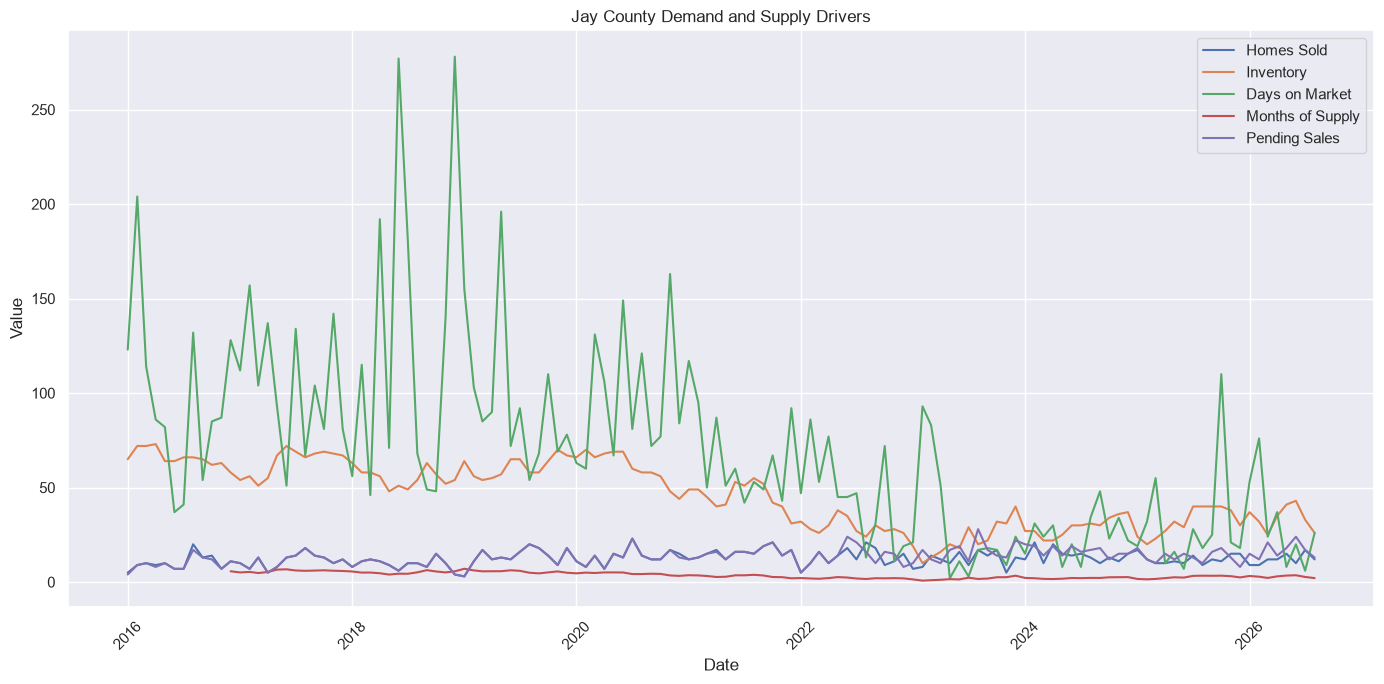

In [24]:

sns.set_theme(style='darkgrid')

plt.figure(figsize=(14, 7))

sns.lineplot(data=Jay, x='PERIOD BEGIN', y='HOMES SOLD', label='Homes Sold')
sns.lineplot(data=Jay, x='PERIOD BEGIN', y='INVENTORY', label='Inventory')
sns.lineplot(data=Jay, x='PERIOD BEGIN', y='MEDIAN DAYS ON MARKET (DAYS)', label='Days on Market')
sns.lineplot(data=Jay, x='PERIOD BEGIN', y='MOS', label='Months of Supply')
sns.lineplot(data=Jay, x='PERIOD BEGIN', y='PENDING SALES', label='Pending Sales')

plt.title('Jay County Demand and Supply Drivers')
plt.ylabel('Value')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

---

#### 3.A) Evaluating Trend-Conforming Counties
Our focus will now shift to understanding why Adams, Allen, Huntington, Wells, and Whitley counties all follow the same trend of bouncing between seller and balanced markets. Examining prosperous counties and determining why they exhibit traits of a strong housing market is equally important as investigating outliers.

---
#### 3.B) Observations

- ###### Median Listing Prices are around two hundrend thousand dollars (200,000) ; Contrastingly, Jay county's median lising price is eighty two thousand dollars (82,000)

- ###### 25 day avergae DOM of Upstate Alliance counties

- ###### Allen county makes up 80% Upstate Alliance inventory

- ###### Adams county MoS upward velocity increase -15.73% Active Listing YOY, -13.37 Pending Sales YOY
    ###### Possible reasons: Housing Problems, 75k-100k House Hold Income Growth down 2%; 16%->14% Growth
    ###### (sources: https://datausa.io/profile/geo/adams-county-in#housing)

- ###### Whitely county MoS negative velcoity 60% rise in hosuing demand
    ###### Possible reasons: 0.5% population boost 2025, downward trend of homeowners with mortgage,  
    ###### (sources: https://www.hoosierdata.in.gov/profiles.asp?scope_choice=a&county_changer=18183&button1=Get+Profile&id=2&page_path=Area+Profiles&path_id=11&menu_level=smenu1&panel_number=1, https://datausa.io/profile/geo/adams-county-in?compare=whitley-county-in&compare_rentMortgage=homeownersMortgage)

- ###### Indiana unemployment rates descending, current Indiana unemployment 3.3%
    ###### (sources:https://fred.stlouisfed.org/series/INUR)

- ###### Indiana population on a linear rise, most recent census population Indiana ; 6,973,333 (2025)
    ###### (sources:https://fred.stlouisfed.org/series/INPOP)


In [25]:
current_status[['REGION NAME', 'PERIOD BEGIN', 'MOS', 'INVENTORY', 'CLOSED SALES TRAILING 12MO', 'ACTIVE LISTINGS', 'ACTIVE LISTINGS YOY (%)', 'PENDING SALES', 'PENDING SALES YOY (%)', 'HOMES SOLD', 'MEDIAN DAYS ON MARKET (DAYS)', 'MEDIAN NEW LISTING PRICE ($)']]

,REGION NAME,PERIOD BEGIN,MOS,INVENTORY,CLOSED SALES TRAILING 12MO,ACTIVE LISTINGS,ACTIVE LISTINGS YOY (%),PENDING SALES,PENDING SALES YOY (%),HOMES SOLD,MEDIAN DAYS ON MARKET (DAYS),MEDIAN NEW LISTING PRICE ($)
1635,"Adams County, IN",2026-08-01,1.354086,29.0,257.0,65.0,-15.73,28.0,-13.37,23.0,26.0,206450.0
667,"Allen County, IN",2026-08-01,2.178475,1007.0,5547.0,1617.0,-3.87,597.0,0.42,548.0,20.0,261043.0
1625,"Huntington County, IN",2026-08-01,2.246696,85.0,454.0,131.0,4.64,42.0,0.22,45.0,23.0,226109.0
2402,"Jay County, IN",2026-08-01,2.093960,26.0,149.0,39.0,-23.26,13.0,33.47,12.0,26.0,82038.0
1725,"Wells County, IN",2026-08-01,2.167224,54.0,299.0,91.0,7.90,40.0,21.33,26.0,29.0,241433.0
668,"Whitley County, IN",2026-08-01,1.909814,60.0,377.0,112.0,6.91,51.0,60.42,35.0,22.0,275825.0


---

#### 3.C) Coming to a Conclusion
Population growth in the Upstate Alliance is fueling higher housing demand, which is subsequently driving down months of supply (MoS).
###### (sources:https://www.wane.com/news/local-news/as-northeast-indiana-grows-to-1-million-residents-the-biggest-hurdle-is-housing/ )
nally, another driving force behind the negative velocity of months of supply is the employment growth of Northeast Indiana. Indiana’s unemployment rate is 3.3%, while the national rate is 4.1%.
###### (sources:https://www.in.gov/dwd/newsroom/employment-reports/ )

In conclusion, the driving forces behind Northeast Indiana’s seller’s market are a steady influx of jobs and a growing population. Together, these two factors fuel high demand for housing, which reduces the time it would take to sell all homes (MoS). At the current rate, it is safe to say that Northeast Indiana is in a firm seller’s market, unless something completely unexpected occurs, such as a sudden recession or pandemic. Allen County and other counties with a high volume of inventory will likely remain in a seller’s market for a while.


---

## Creating Velocity Model
----------------------
This was the first model built, It relys on metric factors e.g. Lags and Differences. This model is only capable of predicting momentum which is incredibly valuable, but CANNOT account for buyer sentiement and pyshcological factors. Why Is This Model Can Still Be Valuable to The North Eastern Group? This model is still valuable to your corporation; because it gives agents a quick tool to look over short term predictions and a baseline for possible actions.

Important Disclaimer: This Model is ONLY capable of capturing the velocity and acceleration of months of supply, sudden changes in the power balance of buyers and sellers will NOT be captured by the model. This Model is meant to assist agents with pricing startegy and a reference point. This model's intended purpose is to capture sensitive turning points and to give North Eastern agents an edge in regular market periods.

In [44]:
Allen = df_NEast[(df_NEast['REGION NAME'] == 'Allen County, IN')].copy()                                                                                                                                          
Allen = Allen.sort_values('PERIOD BEGIN').copy()                                  

Allen['MONTH'] = Allen['PERIOD BEGIN'].dt.month                                                                            
Allen['MONTH_SIN'] = np.sin(2 * np.pi * Allen['MONTH']/12)                                                                               
Allen['MONTH_COS'] = np.cos(2 * np.pi * Allen['MONTH']/12)                                                                     
Allen['QUARTER'] = Allen['PERIOD BEGIN'].dt.quarter                                                            
Allen['NEXT MONTH MOS'] = (Allen['MOS'].shift(-1))                                                                    
Allen['NEXT MOS CHANGE'] = Allen['MOS'].shift(-1)- Allen['MOS']

Allen['1 MONTH LAG MOS'] = Allen['MOS'].shift(1)                                                                                       
Allen['3 MONTH LAG MOS'] = Allen['MOS'].shift(3)
Allen['6 MONTH LAG MOS'] = Allen['MOS'].shift(6)
Allen['12 MONTH LAG MOS'] = Allen['MOS'].shift(12)
Allen['1MO CHANGE MOS'] = Allen['MOS'].diff(1)                                                                                                                   
Allen['3MO CHANGE MOS'] = Allen['MOS'].diff(3)
Allen['6MO CHANGE MOS'] = Allen['MOS'].diff(6)
Allen['12MO CHANGE MOS'] = Allen['MOS'].diff(12)

Allen['1 MONTH LAG DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].shift(1)                                                                         
Allen['3 MONTH LAG DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].shift(3)
Allen['6 MONTH LAG DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].shift(6)
Allen['12 MONTH LAG DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].shift(12)
Allen['1MO CHANGE DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].diff()                                                     
Allen['3MO CHANGE DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].diff(3)
Allen['6MO CHANGE DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].diff(6)
Allen['12MO CHANGE DOM'] = Allen['MEDIAN DAYS ON MARKET (DAYS)'].diff(12)
                                                                                                                                                                                            
Allen['1 MONTH LAG INV'] = Allen['INVENTORY'].shift(1)                         
Allen['3 MONTH LAG INV'] = Allen['INVENTORY'].shift(3)
Allen['6 MONTH LAG INV'] = Allen['INVENTORY'].shift(6)
Allen['12 MONTH LAG INV'] = Allen['INVENTORY'].shift(12)
Allen['1MO CHANGE INV'] = Allen['INVENTORY'].diff()
Allen['3MO CHANGE INV'] = Allen['INVENTORY'].diff(3)
Allen['6MO CHANGE INV'] = Allen['INVENTORY'].diff(6)
Allen['12MO CHANGE INV'] = Allen['INVENTORY'].diff(12)



q1 = Allen['TRUE MOS'].quantile(0.25)                                                                                   

q3 = Allen['TRUE MOS'].quantile(0.75)

iqr = q3 - q1                                
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

Allen['MOS_OUTLIER'] = ((Allen['MOS'] < lower_bound) | (Allen['MOS'] > upper_bound))

                                                                                                                                                   
features = [
    '1 MONTH LAG MOS',
    '3 MONTH LAG MOS',
    '6 MONTH LAG MOS',
    '12 MONTH LAG MOS',
    '1 MONTH LAG DOM',
    '3 MONTH LAG DOM',
    '6 MONTH LAG DOM',
    '12 MONTH LAG DOM',
    '1 MONTH LAG INV',
    '3 MONTH LAG INV',
    '6 MONTH LAG INV',
    '12 MONTH LAG INV',
    '1MO CHANGE MOS',
    '3MO CHANGE MOS',
    '6MO CHANGE MOS',
    '12MO CHANGE MOS',
    '1MO CHANGE DOM',
    '3MO CHANGE DOM',
    '6MO CHANGE DOM', 
    '12MO CHANGE DOM',
    '1MO CHANGE INV',
    '3MO CHANGE INV',
    '6MO CHANGE INV',
    '12MO CHANGE INV',
    'MONTH_SIN',
    'MONTH_COS',
    'MOS_OUTLIER', 
    'QUARTER'
]


                                                                            
AllenModelData = Allen[features + ['NEXT MOS CHANGE', 'NEXT MONTH MOS', 'MOS', 'PERIOD BEGIN']].dropna()

AllenTraining = AllenModelData[(AllenModelData['PERIOD BEGIN'] >= '2023-01-01') & (AllenModelData['PERIOD BEGIN'] < '2026-01-01')]
AllenTesting = AllenModelData[AllenModelData['PERIOD BEGIN'] >= '2026-01-01']

AllenX_train = AllenTraining[features]
AllenY_train = AllenTraining['NEXT MOS CHANGE']                                   
AllenX_test = AllenTesting[features]
AllenY_test = AllenTesting['NEXT MONTH MOS']                                                     

model = RandomForestRegressor(n_estimators=103, random_state=42, max_depth=4, min_samples_leaf=4, max_features=.01)
model.fit(AllenX_train, AllenY_train)

AllenPredictedChange = model.predict(AllenX_test)
AllenPredictions = AllenTesting['MOS'].values + AllenPredictedChange                             

mae = mean_absolute_error(AllenY_test, AllenPredictions)
naive_mae = mean_absolute_error(AllenY_test, AllenTesting['MOS'])                                      

print(f'Test set size: {len(AllenY_test)} rows')
print(f'Model MAE: {mae:.3f} months')
print(f'Naive MAE: {naive_mae:.3f} months')

importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)

AllenComparison = pd.DataFrame({
    'TODAY': AllenTesting['MOS'].values,
    'PREDICTED CHANGE': AllenPredictedChange,
    'MODEL PREDICTION': AllenPredictions,
    'ACTUAL': AllenY_test.values,
})

                                                                               
horizons = [1, 2, 3, 4, 5, 6,]
forecast = {}

for horizon in horizons:
    Allen[f'CHANGE +{horizon}'] = Allen['MOS'].shift(-horizon) - Allen['MOS']
    Adata = Allen[Allen['PERIOD BEGIN'] >= '2023-01-01'][features + [f'CHANGE +{horizon}']].dropna()

    AModel = RandomForestRegressor(n_estimators=103, random_state=42, max_depth=4, min_samples_leaf=4, max_features=.01)
    AModel.fit(Adata[features], Adata[f'CHANGE +{horizon}'])

    last_row = Allen[features].dropna().iloc[[-1]]                                            
    change = AModel.predict(last_row)[0]                                           
    today = Allen.loc[last_row.index[0], 'MOS']                                          
    forecast[horizon] = round(today + change, 2)                                         

print(f"Forecasted Months of Supply in 6 months: {forecast[6]} months")
print(f"Forecasted Months of Supply in 3 months: {forecast[3]} months")
print(f"Forecasted Months of Supply in 1 month: {forecast[1]} months")
naive_forecast = Allen['MOS'].iloc[-1]
print(f'NaiveForecast: {naive_forecast:.2f}')
print(AllenComparison)

Test set size: 7 rows
Model MAE: 0.033 months
Naive MAE: 0.079 months
Forecasted Months of Supply in 6 months: 2.06 months
Forecasted Months of Supply in 3 months: 2.21 months
Forecasted Months of Supply in 1 month: 2.22 months
NaiveForecast: 2.18
      TODAY  PREDICTED CHANGE  MODEL PREDICTION    ACTUAL
0  1.880266         -0.064626          1.815640  1.815089
1  1.815089         -0.023209          1.791880  1.751244
2  1.751244          0.008633          1.759876  1.821037
3  1.821037          0.057765          1.878803  1.900236
4  1.900236          0.068489          1.968724  1.997812
5  1.997812          0.068414          2.066226  2.142160
6  2.142160          0.039199          2.181358  2.178475


## Visualizing Output 

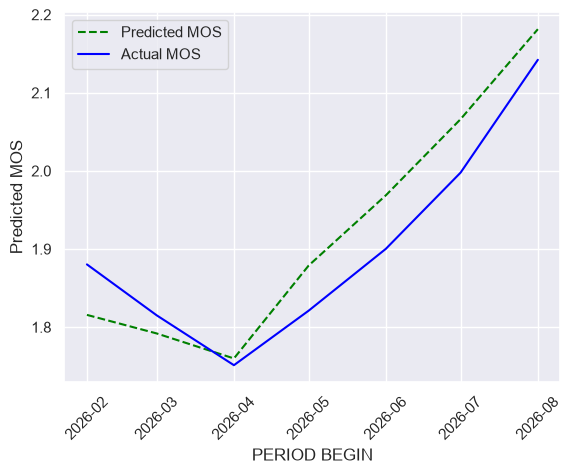

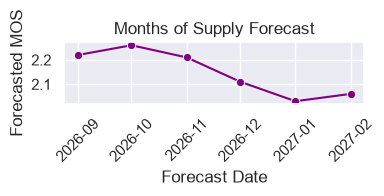

In [28]:
plot_df= pd.DataFrame({
    'PERIOD BEGIN': AllenTesting['PERIOD BEGIN'] + pd.DateOffset(months=1),
    'Actual MOS': AllenTesting['MOS'].values,
    'Predicted MOS': AllenPredictions,
})

sns.set_theme(style='darkgrid')

plt.Figure(figsize=(2, 2))

sns.lineplot(
    data=plot_df,
    x = 'PERIOD BEGIN',
    y = 'Predicted MOS',
    label = "Predicted MOS",
    color = "green",
    linestyle = "--",
)
sns.lineplot(
    data= plot_df,
    x = 'PERIOD BEGIN',
    y =  'Actual MOS',
    label = "Actual MOS",
    color = "blue",
)


plt.xticks(rotation=45)
plt.show()

# build forecast dataframe
forecast_dates = [Allen['PERIOD BEGIN'].max() + pd.DateOffset(months=h) for h in horizons]
forecast_df = pd.DataFrame({
    'PERIOD BEGIN': forecast_dates,
    'Forecasted MOS': [forecast[h] for h in horizons]
})

sns.set_theme(style='darkgrid')

plt.figure(figsize=(4, 2))
sns.lineplot(
    data=forecast_df,
    x='PERIOD BEGIN',
    y='Forecasted MOS',
    marker='o',
    color='purple'
)

plt.title('Months of Supply Forecast')
plt.xlabel('Forecast Date')
plt.ylabel('Forecasted MOS')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Creating Velocity 2nd Model
----------------------
This was the second model built, It relys on metric factors e.g. Lags and Differences. This model is only capable of predicting momentum which is incredibly valuable, but CANNOT account for buyer sentiement and pyshcological factors. Why Is This Model Can Still Be Valuable to The North Eastern Group? This model is still valuable to your corporation; because it gives agents a quick tool to look over REGIONAL short term predictions and a baseline for possible actions.

Important Disclaimer: This Model is ONLY capable of capturing the velocity and acceleration of months of supply, sudden changes in the power balance of buyers and sellers will NOT be captured by the model. This Model is meant to assist agents with pricing startegy and a reference point. This model's intended purpose is to capture sensitive turning points and to give North Eastern agents an edge in regular market periods.

In [29]:
RegionalForecast = df_NEast.groupby('PERIOD BEGIN').agg({'INVENTORY': 'sum', 'HOMES SOLD': 'sum', 'ACTIVE LISTINGS': 'sum', 'PENDING SALES': 'sum', 'MEDIAN DAYS ON MARKET (DAYS)': 'mean'}).reset_index()

RegionalForecast['REGIONAL MOS'] = RegionalForecast['ACTIVE LISTINGS'] / RegionalForecast['HOMES SOLD']

RegionalForecast['MONTH'] = RegionalForecast['PERIOD BEGIN'].dt.month
RegionalForecast['MONTH_SIN'] = np.sin(2 * np.pi * RegionalForecast['MONTH']/12)
RegionalForecast['MONTH_COS'] = np.cos(2 * np.pi * RegionalForecast['MONTH']/12)
RegionalForecast['CLOSED SALES TRAILING 12MO'] = RegionalForecast['HOMES SOLD'].rolling(12).sum()
RegionalForecast['MOS'] = RegionalForecast['INVENTORY'] / (RegionalForecast['CLOSED SALES TRAILING 12MO'] / 12)
RegionalForecast['QUARTER'] = RegionalForecast['PERIOD BEGIN'].dt.quarter
RegionalForecast['NEXT REGIONAL MONTH MOS'] = (RegionalForecast['MOS'].shift(-1))
RegionalForecast['NEXT MOS CHANGE'] = RegionalForecast['MOS'].shift(-1)- RegionalForecast['MOS']


RegionalForecast['1 MONTH REGIONAL MOS LAG'] = RegionalForecast['MOS'].shift(1)
RegionalForecast['3 MONTH REGIONAL MOS LAG'] = RegionalForecast['MOS'].shift(3)
RegionalForecast['6 MONTH REGIONAL MOS LAG'] = RegionalForecast['MOS'].shift(6)
RegionalForecast['12 MONTH REGIONAL MOS LAG'] = RegionalForecast['MOS'].shift(12)
RegionalForecast['REGIONAL 1MO CHANGE MOS'] = RegionalForecast['MOS'].diff()
RegionalForecast['REGIONAL 3MO CHANGE MOS'] = RegionalForecast['MOS'].diff(3)
RegionalForecast['REGIONAL 6MO CHANGE MOS'] = RegionalForecast['MOS'].diff(6)
RegionalForecast['REGIONAL 12MO CHANGE MOS'] = RegionalForecast['MOS'].diff(12)


RegionalForecast['1 MONTH REGIONAL DOM LAG'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].shift(1)
RegionalForecast['3 MONTH REGIONAL DOM LAG'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].shift(3)
RegionalForecast['6 MONTH REGIONAL DOM LAG'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].shift(6)
RegionalForecast['12 MONTH REGIONAL DOM LAG'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].shift(12)
RegionalForecast['REGIONAL 1MO CHANGE DOM'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].diff()
RegionalForecast['REGIONAL 3MO CHANGE DOM'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].diff(3)
RegionalForecast['REGIONAL 6MO CHANGE DOM'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].diff(6)
RegionalForecast['REGIONAL 12MO CHANGE DOM'] = RegionalForecast['MEDIAN DAYS ON MARKET (DAYS)'].diff(12)

RegionalForecast['1 MONTH REGIONAL INV LAG'] = RegionalForecast['INVENTORY'].shift(1)
RegionalForecast['3 MONTH REGIONAL INV LAG'] = RegionalForecast['INVENTORY'].shift(3)
RegionalForecast['6 MONTH REGIONAL INV LAG'] = RegionalForecast['INVENTORY'].shift(6)
RegionalForecast['12 MONTH REGIONAL INV LAG'] = RegionalForecast['INVENTORY'].shift(12)
RegionalForecast['REGIONAL 1MO CHANGE INV'] = RegionalForecast['INVENTORY'].diff()
RegionalForecast['REGIONAL 3MO CHANGE INV'] = RegionalForecast['INVENTORY'].diff(3)
RegionalForecast['REGIONAL 6MO CHANGE INV'] = RegionalForecast['INVENTORY'].diff(6)
RegionalForecast['REGIONAL 12MO CHANGE INV'] = RegionalForecast['INVENTORY'].diff(12)









quantile1 = RegionalForecast['MOS'].quantile(0.25)

quantile3 = RegionalForecast['MOS'].quantile(0.75)

intqr = quantile3 - quantile1
lower_boundA = quantile1 - 1.5 * intqr
upper_boundA = quantile3 + 1.5 * intqr

RegionalForecast['MOS_OUTLIER'] = ((RegionalForecast['MOS'] < lower_boundA) | (RegionalForecast['MOS'] > upper_boundA))

RegionalFeatures = [
    '1 MONTH REGIONAL MOS LAG',
    '3 MONTH REGIONAL MOS LAG',
    '6 MONTH REGIONAL MOS LAG',
    '12 MONTH REGIONAL MOS LAG',
    '1 MONTH REGIONAL DOM LAG',
    '3 MONTH REGIONAL DOM LAG',
    '6 MONTH REGIONAL DOM LAG',
    '12 MONTH REGIONAL DOM LAG',
    '1 MONTH REGIONAL INV LAG',
    '3 MONTH REGIONAL INV LAG',
    '6 MONTH REGIONAL INV LAG',
    '12 MONTH REGIONAL INV LAG',
    'REGIONAL 1MO CHANGE MOS',
    'REGIONAL 3MO CHANGE MOS',
    'REGIONAL 6MO CHANGE MOS',
    'REGIONAL 12MO CHANGE MOS',
    'REGIONAL 1MO CHANGE DOM',
    'REGIONAL 3MO CHANGE DOM',
    'REGIONAL 6MO CHANGE DOM',
    'REGIONAL 12MO CHANGE DOM',
    'REGIONAL 1MO CHANGE INV',
    'REGIONAL 3MO CHANGE INV',
    'REGIONAL 6MO CHANGE INV',
    'REGIONAL 12MO CHANGE INV',
    'MONTH_SIN',
    'MONTH_COS',
    'MOS_OUTLIER', 
    'QUARTER'
]






Regional_Model_Data = RegionalForecast[RegionalFeatures + ['NEXT REGIONAL MONTH MOS', 'NEXT MOS CHANGE', 'PERIOD BEGIN', 'MOS']].dropna()

RegionalTraining = Regional_Model_Data[(RegionalForecast.loc[Regional_Model_Data.index, 'PERIOD BEGIN'] >= '2023-01-01') & (RegionalForecast.loc[Regional_Model_Data.index, 'PERIOD BEGIN'] < '2026-01-01')].copy()
RegionalTest = Regional_Model_Data[RegionalForecast.loc[Regional_Model_Data.index, 'PERIOD BEGIN'] >= '2026-01-01'].copy()

RegionalX_Train = RegionalTraining[RegionalFeatures]
Regionaly_Train = RegionalTraining['NEXT MOS CHANGE']
RegionalX_Test = RegionalTest[RegionalFeatures]
Regionaly_Test = RegionalTest['NEXT REGIONAL MONTH MOS']

RegionalModel = RandomForestRegressor( n_estimators = 103, random_state=42, max_depth=4, min_samples_leaf=4, max_features= .01)

RegionalModel.fit(RegionalX_Train, Regionaly_Train)

RegionalPredictedChange = RegionalModel.predict(RegionalX_Test)
RegionalPredictions = RegionalTest['MOS'].values + RegionalPredictedChange

RegionalMAE = mean_absolute_error(Regionaly_Test, RegionalPredictions)
Naive_Regional_MAE = mean_absolute_error(Regionaly_Test, RegionalTest['MOS'])


print(f'Test set size: {len(Regionaly_Test)} rows')
print(f'Model MAE: {RegionalMAE:.3f} months')
print(f'Naive MAE: {Naive_Regional_MAE:.3f} months')

RegionalImportances = pd.Series(RegionalModel.feature_importances_, index=RegionalFeatures).sort_values(ascending=False)

predictionsB = RegionalModel.predict(RegionalX_Test)

RegionalComparison = pd.DataFrame({
    'TODAY': RegionalTest['MOS'].values,
    'PREDICTED CHANGE': RegionalPredictedChange,
    'MODEL PREDICTION': RegionalPredictions,
    'ACTUAL': Regionaly_Test.values,
})

regional_forecast = {}

for horizon in horizons:
    RegionalForecast[f'CHANGE +{horizon}'] = RegionalForecast['MOS'].shift(-horizon) - RegionalForecast['MOS']

    Rdata = RegionalForecast[RegionalForecast['PERIOD BEGIN'] >= '2023-01-01'][RegionalFeatures + [f'CHANGE +{horizon}']].dropna()
    RModel = RandomForestRegressor(n_estimators=181, random_state=42, max_depth=2, min_samples_leaf=4, max_features=.01)
    RModel.fit(Rdata[RegionalFeatures], Rdata[f'CHANGE +{horizon}'])
    Rlast_row = RegionalForecast[RegionalFeatures].dropna().iloc[[-1]]
    Regionalchange = RModel.predict(Rlast_row)[0]
    Regionaltoday = RegionalForecast.loc[Rlast_row.index[0], 'MOS']
    regional_forecast[horizon] = round(Regionaltoday + Regionalchange, 2)

print(f"Forecasted months of supply in 6 months: {regional_forecast[6]}")
print(f"Forecasted months of supply in 3 months: {regional_forecast[3]}")
print(f"Forecasted months of supply in 1 month: {regional_forecast[1]}")
Rnaive_forecast = RegionalForecast['MOS'].iloc[-1]
print(f'Regional Naive Forecas: {Rnaive_forecast:.2f}')
print(RegionalComparison)

Test set size: 7 rows
Model MAE: 0.048 months
Naive MAE: 0.081 months
Forecasted months of supply in 6 months: 2.0
Forecasted months of supply in 3 months: 2.12
Forecasted months of supply in 1 month: 2.17
Regional Naive Forecas: 2.14
      TODAY  PREDICTED CHANGE  MODEL PREDICTION    ACTUAL
0  1.847218         -0.041236          1.805983  1.772510
1  1.772510         -0.029419          1.743092  1.707373
2  1.707373          0.005983          1.713356  1.825342
3  1.825342          0.070364          1.895706  1.915837
4  1.915837          0.081208          1.997045  1.965222
5  1.965222          0.069090          2.034312  2.106961
6  2.106961          0.061426          2.168387  2.136383


## Visualization

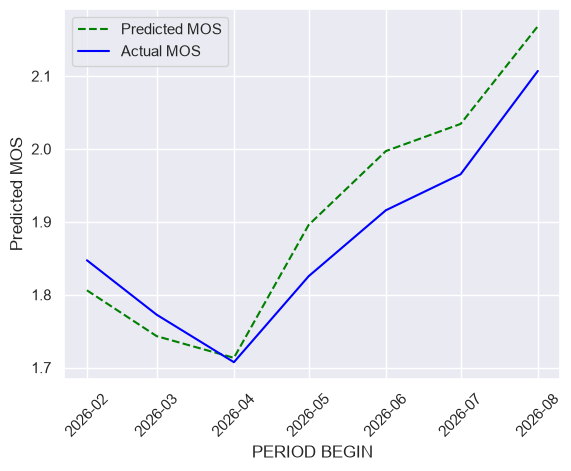

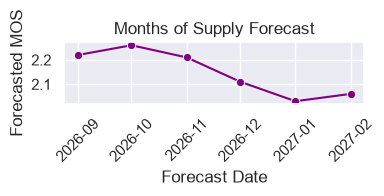

In [30]:
plot_df= pd.DataFrame({
    'PERIOD BEGIN': RegionalTest['PERIOD BEGIN'] + pd.DateOffset(months=1),
    'Actual MOS': RegionalTest['MOS'].values,
    'Predicted MOS': RegionalPredictions,
})

sns.set_theme(style='darkgrid')

plt.Figure(figsize=(2, 2))

sns.lineplot(
    data=plot_df,
    x = 'PERIOD BEGIN',
    y = 'Predicted MOS',
    label = "Predicted MOS",
    color = "green",
    linestyle = "--",
)
sns.lineplot(
    data= plot_df,
    x = 'PERIOD BEGIN',
    y =  'Actual MOS',
    label = "Actual MOS",
    color = "blue",
)


plt.xticks(rotation=45)
plt.show()

# build forecast dataframe
forecast_dates = [RegionalForecast['PERIOD BEGIN'].max() + pd.DateOffset(months=h) for h in horizons]
forecast_df = pd.DataFrame({
    'PERIOD BEGIN': forecast_dates,
    'Forecasted MOS': [forecast[h] for h in horizons]
})

sns.set_theme(style='darkgrid')

plt.figure(figsize=(4, 2))
sns.lineplot(
    data=forecast_df,
    x='PERIOD BEGIN',
    y='Forecasted MOS',
    marker='o',
    color='purple'
)

plt.title('Months of Supply Forecast')
plt.xlabel('Forecast Date')
plt.ylabel('Forecasted MOS')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Exports

In [31]:
last_date = Allen['PERIOD BEGIN'].max()
rows = []
for h in horizons:
    rows.append({
        'Market': 'Allen County, IN',
        'Horizon': h,
        'Forecast Date': last_date + pd.DateOffset(months=h),
        'Forecasted MOS': forecast[h],
    })
                                                                                     
backtest = pd.DataFrame({
    'Market': 'Allen County, IN',
    'Type': 'Model Testing',
    'Horizon': 0,
    'Forecast Date': (Allen.loc[AllenTesting.index, 'PERIOD BEGIN'] + pd.DateOffset(months=1)).to_numpy(),
    'Forecasted MOS': AllenPredictions,
    'Actual MOS': AllenY_test.to_numpy(),
})

                                                              
future = pd.DataFrame(rows).rename(columns={'ForecastMOS': 'PredictedMOS'})
future['Type'] = 'Forecast'
future['ActualMOS'] = np.nan                                      

AllenPrediction_Export = pd.concat([backtest, future], ignore_index=True)

Path("reports").mkdir(exist_ok=True)
AllenPrediction_Export.to_csv("reports/allen_predictions.csv", index=False)

In [32]:
last_date = RegionalForecast['PERIOD BEGIN'].max()
rows = []
for h in horizons:
    rows.append({
        'Market': 'Regional',
        'Horizon': h,
        'Forecast Date': last_date + pd.DateOffset(months=h),
        'Forecasted MOS': regional_forecast[h],
    })
                                                                                     
backtest = pd.DataFrame({
    'Market': 'Regional',
    'Type': 'Model Testing',
    'Horizon': 0,
    'Forecast Date': (RegionalForecast.loc[RegionalTest.index, 'PERIOD BEGIN'] + pd.DateOffset(months=1)).to_numpy(),
    'Forecasted MOS': RegionalPredictions,
    'ActualMOS': Regionaly_Test.to_numpy(),
})

                                                              
future = pd.DataFrame(rows).rename(columns={'ForecastMOS': 'PredictedMOS'})
future['Type'] = 'Forecast'
future['ActualMOS'] = np.nan                                      

RegionalPredictions_Export = pd.concat([backtest, future], ignore_index=True)

Path("reports").mkdir(exist_ok=True)
RegionalPredictions_Export.to_csv("reports/Regional_predictions.csv", index=False)

## Conclusion


---
### IN PROGRESS
---

In [ ]:
Huntington = df_NEast[(df_NEast['REGION NAME'] == 'Huntington County, IN')].copy()
Huntington = Huntington.sort_values('PERIOD BEGIN').copy()

Huntington['MONTH'] = Huntington['PERIOD BEGIN'].dt.month
Huntington['MONTH_SIN'] = np.sin(2 * np.pi * Huntington['MONTH']/12)
Huntington['MONTH_COS'] = np.cos(2 * np.pi * Huntington['MONTH']/12)
Huntington['QUARTER'] = Huntington['PERIOD BEGIN'].dt.quarter
Huntington['NEXT MONTH MOS'] = (Huntington['MOS'].shift(-1))
Huntington['NEXT MOS CHANGE'] = Huntington['MOS'].shift(-1) - Huntington['MOS']

Huntington['1 MONTH LAG MOS'] = Huntington['MOS'].shift(1)
Huntington['3 MONTH LAG MOS'] = Huntington['MOS'].shift(3)
Huntington['6 MONTH LAG MOS'] = Huntington['MOS'].shift(6)
Huntington['12 MONTH LAG MOS'] = Huntington['MOS'].shift(12)
Huntington['1MO CHANGE MOS'] = Huntington['MOS'].diff(1)
Huntington['3MO CHANGE MOS'] = Huntington['MOS'].diff(3)
Huntington['6MO CHANGE MOS'] = Huntington['MOS'].diff(6)
Huntington['12MO CHANGE MOS'] = Huntington['MOS'].diff(12)

Huntington['1 MONTH LAG DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].shift(1)
Huntington['3 MONTH LAG DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].shift(3)
Huntington['6 MONTH LAG DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].shift(6)
Huntington['12 MONTH LAG DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].shift(12)
Huntington['1MO CHANGE DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].diff()
Huntington['3MO CHANGE DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].diff(3)
Huntington['6MO CHANGE DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].diff(6)
Huntington['12MO CHANGE DOM'] = Huntington['MEDIAN DAYS ON MARKET (DAYS)'].diff(12)

Huntington['1 MONTH LAG INV'] = Huntington['INVENTORY'].shift(1)
Huntington['3 MONTH LAG INV'] = Huntington['INVENTORY'].shift(3)
Huntington['6 MONTH LAG INV'] = Huntington['INVENTORY'].shift(6)
Huntington['12 MONTH LAG INV'] = Huntington['INVENTORY'].shift(12)
Huntington['1MO CHANGE INV'] = Huntington['INVENTORY'].diff()
Huntington['3MO CHANGE INV'] = Huntington['INVENTORY'].diff(3)
Huntington['6MO CHANGE INV'] = Huntington['INVENTORY'].diff(6)
Huntington['12MO CHANGE INV'] = Huntington['INVENTORY'].diff(12)


Hq1 = Huntington['TRUE MOS'].quantile(0.25)

Hq3 = Huntington['TRUE MOS'].quantile(0.75)

Hiqr = Hq3 - Hq1
Hlower_bound = Hq1 - 1.5 * Hiqr
Hupper_bound = Hq3 + 1.5 * Hiqr

Huntington['MOS_OUTLIER'] = ((Huntington['MOS'] < Hlower_bound) | (Huntington['MOS'] > Hupper_bound))


features = [
    'CLOSED SALES TRAILING 12MO',
    'PENDING SALES YOY (%)',
    'ACTIVE LISTINGS YOY (%)',
    '1 MONTH LAG MOS',
    '3 MONTH LAG MOS',
    '6 MONTH LAG MOS',
    '12 MONTH LAG MOS',
    '1 MONTH LAG DOM',
    '3 MONTH LAG DOM',
    '6 MONTH LAG DOM',
    '12 MONTH LAG DOM',
    '1 MONTH LAG INV',
    '3 MONTH LAG INV',
    '6 MONTH LAG INV',
    '12 MONTH LAG INV',
    '1MO CHANGE MOS',
    '3MO CHANGE MOS',
    '6MO CHANGE MOS',
    '12MO CHANGE MOS',
    '1MO CHANGE DOM',
    '3MO CHANGE DOM',
    '6MO CHANGE DOM',
    '12MO CHANGE DOM',
    '1MO CHANGE INV',
    '3MO CHANGE INV',
    '6MO CHANGE INV',
    '12MO CHANGE INV',
    'MONTH_SIN',
    'MONTH_COS',
    'MOS_OUTLIER',
    'QUARTER'
]


HuntingtonModelData = Huntington[features + ['NEXT MOS CHANGE', 'NEXT MONTH MOS', 'MOS', 'PERIOD BEGIN']].dropna()

HuntingtonTraining = HuntingtonModelData[(HuntingtonModelData['PERIOD BEGIN'] >= '2023-01-01') & (HuntingtonModelData['PERIOD BEGIN'] < '2026-01-01')]
HuntingtonTesting = HuntingtonModelData[HuntingtonModelData['PERIOD BEGIN'] >= '2026-01-01']

HuntingtonX_train = HuntingtonTraining[features]
HuntingtonY_train = HuntingtonTraining['NEXT MOS CHANGE']
HuntingtonX_test = HuntingtonTesting[features]
HuntingtonY_test = HuntingtonTesting['NEXT MONTH MOS']

HuntingtonModel = RandomForestRegressor(n_estimators=300, random_state=42, max_depth=4, min_samples_leaf=4, max_features=.1)
HuntingtonModel.fit(HuntingtonX_train, HuntingtonY_train)

HuntingtonPredictedChange = HuntingtonModel.predict(HuntingtonX_test)
HuntingtonPredictions = HuntingtonTesting['MOS'].values + HuntingtonPredictedChange

Huntington_mae = mean_absolute_error(HuntingtonY_test, HuntingtonPredictions)
Huntington_naive_mae = mean_absolute_error(HuntingtonY_test, HuntingtonTesting['MOS'])

print(f'Test set size: {len(HuntingtonY_test)} rows')
print(f'Model MAE: {Huntington_mae:.3f} months')
print(f'Naive MAE: {Huntington_naive_mae:.3f} months')

HuntingtonImportances = pd.Series(HuntingtonModel.feature_importances_, index=features).sort_values(ascending=False)

HuntingtonComparison = pd.DataFrame({
    'TODAY': HuntingtonTesting['MOS'].values,
    'PREDICTED CHANGE': HuntingtonPredictedChange,
    'MODEL PREDICTION': HuntingtonPredictions,
    'ACTUAL': HuntingtonY_test.values,
})


horizons = [1, 2, 3, 4, 5, 6,]
Huntington_forecast = {}

for horizon in horizons:
    Huntington[f'CHANGE +{horizon}'] = Huntington['MOS'].shift(-horizon) - Huntington['MOS']
    Hdata = Huntington[Huntington['PERIOD BEGIN'] >= '2023-01-01'][features + [f'CHANGE +{horizon}']].dropna()

    HModel = RandomForestRegressor(n_estimators=300, random_state=42, max_depth=4, min_samples_leaf=4, max_features=1)
    HModel.fit(Hdata[features], Hdata[f'CHANGE +{horizon}'])

    Hlast_row = Huntington[features].dropna().iloc[[-1]]
    Hchange = HModel.predict(Hlast_row)[0]
    Htoday = Huntington.loc[Hlast_row.index[0], 'MOS']
    Huntington_forecast[horizon] = round(Htoday + Hchange, 2)

print(f"Forecasted Months of Supply in 6 months: {Huntington_forecast[6]} months")
print(f"Forecasted Months of Supply in 3 months: {Huntington_forecast[3]} months")
print(f"Forecasted Months of Supply in 1 month: {Huntington_forecast[1]} months")
Huntington_naive_forecast = Huntington['MOS'].iloc[-1]
print(f'NaiveForecast: {Huntington_naive_forecast:.2f}')
print(HuntingtonComparison)